In [60]:
import os
import sys
import jieba
import json
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import silhouette_score, calinski_harabasz_score
import matplotlib.pyplot as plt
from wordcloud import WordCloud
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import xgboost as xgb
from sklearn.metrics import f1_score

class SinglePassCluster():
    def __init__(self, stopWords_path="stop_words.txt", my_stopwords=None,
                 max_df=0.5, max_features=1000,
                 simi_threshold=0.5, res_save_path="./cluster_res.json",
                 max_clusters=8):  # 限制聚类个数为8
        
        self.stopwords = self.load_stopwords(stopWords_path)
        if isinstance(my_stopwords, list):
            self.stopwords += my_stopwords
        self.tfidf = TfidfVectorizer(stop_words=self.stopwords, max_df=max_df, max_features=max_features)
        self.simi_thr = simi_threshold
        self.cluster_center_vec = [] # [cluster_center_vec, ]
        self.idx_2_text = {}  # {文本id: text, }
        self.cluster_2_idx = {}  # {cluster_id: [text_id, ]}
        self.res_path = res_save_path  # save self.cluster_2_idx
        self.max_clusters = max_clusters  # 最大聚类数

    def load_stopwords(self, stopWords_path):
        stopwords = []
        if os.path.exists(stopWords_path):
            with open(stopWords_path, 'r', encoding='utf-8') as f:
                stopwords = [line.strip() for line in f if line.strip()]
        return stopwords

    def cut_sentences(self, texts):
        if isinstance(texts, str):
            if texts.endswith('.xlsx'):
                df = pd.read_excel(texts, engine='openpyxl')
                texts = df.iloc[:, 0].astype(str).tolist()
            elif os.path.exists(texts):
                with open(texts, 'r', encoding="utf-8") as f:
                    texts = [line.strip() for line in f]

        # 分词并去除停用词
        texts_cut = [
            [w for w in jieba.lcut(t) if w not in self.stopwords]
            for t in texts
        ]
        self.idx_2_text = {idx: " ".join(words) for idx, words in enumerate(texts_cut)}
        return [" ".join(words) for words in texts_cut]



    def get_tfidf(self, texts_cut):
        tfidf = self.tfidf.fit_transform(texts_cut)
        return tfidf.todense().tolist()

    def cosion_simi(self, vec):
        if not self.cluster_center_vec:
            return 0, 0
        simi = cosine_similarity(np.array([vec]), np.array(self.cluster_center_vec))
        max_idx = np.argmax(simi, axis=1)[0]
        max_val = simi[0][max_idx]
        return max_val, max_idx

    def evaluate_clusters(self, tfidf, labels):
        """新增评估指标"""
        print(f"\n评估指标（{len(set(labels))}个簇）:")
        if len(set(labels)) > 1:
            print(f"轮廓系数: {silhouette_score(tfidf, labels):.4f}")
            print(f"Calinski-Harabasz指数: {calinski_harabasz_score(tfidf, labels):.4f}")
        else:
            print("轮廓系数: N/A (只有一个簇)")
            print("Calinski-Harabasz指数: N/A (只有一个簇)")
        unique, counts = np.unique(labels, return_counts=True)
        print("簇样本分布:", dict(zip(unique, counts)))

    plt.rcParams['font.sans-serif'] = ['SimHei']
    plt.rcParams['axes.unicode_minus'] = False
    def plot_clusters(self, tfidf, labels):
        """二维PCA聚类可视化"""
        # 使用全局PCA类
        pca = PCA(n_components=2)
        reduced = pca.fit_transform(tfidf)
        
        plt.figure(figsize=(10,6))
        scatter = plt.scatter(reduced[:,0], reduced[:,1], c=labels, cmap='viridis', alpha=0.6)
        plt.title('Single-Pass聚类结果（PCA二维降维）')
        plt.xlabel('主成分1')
        plt.ylabel('主成分2')
        plt.colorbar(scatter, label='簇编号')
        plt.show()

    def plot_wordclouds(self, texts, labels):
        """词云可视化"""
        cluster_texts = {}
        for idx, label in enumerate(labels):
            if label not in cluster_texts:
                cluster_texts[label] = []
            cluster_texts[label].extend(texts[idx].split())
        
        for cluster_id, words in cluster_texts.items():
            wordcloud = WordCloud(width=800, height=400, 
                                font_path='simhei.ttf',
                                background_color='white').generate(' '.join(words))
            plt.figure(figsize=(10,5))
            plt.imshow(wordcloud, interpolation='bilinear')
            plt.title(f'簇 {cluster_id} 关键词词云')
            plt.axis('off')
            plt.show()

    def plot_bar_distribution(self, labels):
        """新增柱状图可视化簇分布"""
        unique, counts = np.unique(labels, return_counts=True)
        plt.figure(figsize=(8,5))
        plt.bar(unique, counts, color='skyblue')
        plt.xlabel('簇编号')
        plt.ylabel('样本数量')
        plt.title('簇分布柱状图')
        plt.show()

    def plot_pie_distribution(self, labels):
        """美化后的饼图可视化簇分布"""
        unique, counts = np.unique(labels, return_counts=True)
        colors = plt.cm.Set3(np.linspace(0, 1, len(unique)))
        explode = [0.05] * len(unique)  # 突出显示每个扇区
        plt.figure(figsize=(8, 8))
        wedges, texts, autotexts = plt.pie(
            counts, 
            labels=[f'簇 {u}' for u in unique], 
            autopct='%1.1f%%', 
            startangle=140, 
            colors=colors,
            explode=explode,
            textprops={'fontsize': 14},
            wedgeprops={'edgecolor': 'white', 'linewidth': 2}
        )
        plt.setp(autotexts, size=14, weight="bold", color="navy")
        plt.setp(texts, size=14)
        plt.title('簇分布饼图', fontsize=18, fontweight='bold')
        plt.axis('equal')
        plt.tight_layout()
        plt.show()

    def single_pass(self, texts):
        texts_cut = self.cut_sentences(texts)
        tfidf = self.get_tfidf(texts_cut)

        for idx, vec in enumerate(tfidf):
            if not self.cluster_center_vec:
                self.cluster_center_vec.append(vec)
                self.cluster_2_idx[0] = [idx]
            else:
                max_simi, max_idx = self.cosion_simi(vec)
                if max_simi >= self.simi_thr:
                    self.cluster_2_idx[max_idx].append(idx)
                else:
                    if len(self.cluster_center_vec) < self.max_clusters:
                        self.cluster_center_vec.append(vec)
                        self.cluster_2_idx[len(self.cluster_2_idx)] = [idx]
                    else:
                        self.cluster_2_idx[max_idx].append(idx)

        labels = [0] * len(tfidf)
        for cluster_id, members in self.cluster_2_idx.items():
            for idx in members:
                labels[idx] = cluster_id
            
        self.evaluate_clusters(np.array(tfidf), labels)
        self.plot_clusters(np.array(tfidf), labels)
        self.plot_wordclouds([self.idx_2_text[idx] for idx in range(len(tfidf))], labels)
        self.plot_bar_distribution(labels)
        self.plot_pie_distribution(labels)

        with open(self.res_path, "w", encoding="utf-8") as f:
            json.dump(self.cluster_2_idx, f, ensure_ascii=False)

        # 新增：SVM 和 XGBoost 分类及混淆矩阵可视化

        X = np.array(tfidf)
        y = np.array(labels)
        X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

        # SVM 分类
        svm_clf = SVC(kernel='linear', random_state=42)
        svm_clf.fit(X_train, y_train)
        y_pred_svm = svm_clf.predict(X_test)
        cm_svm = confusion_matrix(y_test, y_pred_svm)
        plt.figure(figsize=(6,5))
        ConfusionMatrixDisplay(cm_svm).plot(cmap='Blues', values_format='d')
        plt.title('SVM 混淆矩阵')
        plt.show()

        # XGBoost 分类
        xgb_clf = xgb.XGBClassifier(use_label_encoder=False, eval_metric='mlogloss', random_state=42)
        xgb_clf.fit(X_train, y_train)
        y_pred_xgb = xgb_clf.predict(X_test)
        cm_xgb = confusion_matrix(y_test, y_pred_xgb)
        plt.figure(figsize=(6,5))
        ConfusionMatrixDisplay(cm_xgb).plot(cmap='Greens', values_format='d')
        plt.title('XGBoost 混淆矩阵')
        plt.show()

        # 计算并打印SVM和XGBoost的准确率
        svm_acc = np.mean(y_pred_svm == y_test)
        xgb_acc = np.mean(y_pred_xgb == y_test)
        print(f"SVM 分类准确率: {svm_acc:.4f}")
        print(f"XGBoost 分类准确率: {xgb_acc:.4f}")

        # 计算并打印SVM和XGBoost的F1分数
        svm_f1 = f1_score(y_test, y_pred_svm, average='weighted')
        xgb_f1 = f1_score(y_test, y_pred_xgb, average='weighted')
        print(f"SVM 分类F1分数: {svm_f1:.4f}")
        print(f"XGBoost 分类F1分数: {xgb_f1:.4f}")



c:\Users\86182\anaconda3\envs\learn\Lib\site-packages\sklearn\feature_extraction\text.py:402: UserWarning: Your stop_words may be inconsistent with your preprocessing. Tokenizing the stop words generated tokens ['lex', '①①', '①②', '①③', '①④', '①⑤', '①⑥', '①⑦', '①⑧', '①⑨', '①ａ', '①ｂ', '①ｃ', '①ｄ', '①ｅ', '①ｆ', '①ｇ', '①ｈ', '①ｉ', '①ｏ', '②①', '②②', '②③', '②④', '②⑤', '②⑥', '②⑦', '②⑧', '②⑩', '②ａ', '②ｂ', '②ｄ', '②ｅ', '②ｆ', '②ｇ', '②ｈ', '②ｉ', '②ｊ', '③①', '③⑩', '③ａ', '③ｂ', '③ｃ', '③ｄ', '③ｅ', '③ｆ', '③ｇ', '③ｈ', '④ａ', '④ｂ', '④ｃ', '④ｄ', '④ｅ', '⑤ａ', '⑤ｂ', '⑤ｄ', '⑤ｅ', '⑤ｆ', '１２', 'ｌｉ', 'ｚｘｆｉｔｌ'] not in stop_words.
  warnings.warn(



评估指标（8个簇）:
轮廓系数: 0.1653
Calinski-Harabasz指数: 52.2814
簇样本分布: {np.int64(0): np.int64(188), np.int64(1): np.int64(73), np.int64(2): np.int64(98), np.int64(3): np.int64(49), np.int64(4): np.int64(75), np.int64(5): np.int64(95), np.int64(6): np.int64(21), np.int64(7): np.int64(41)}


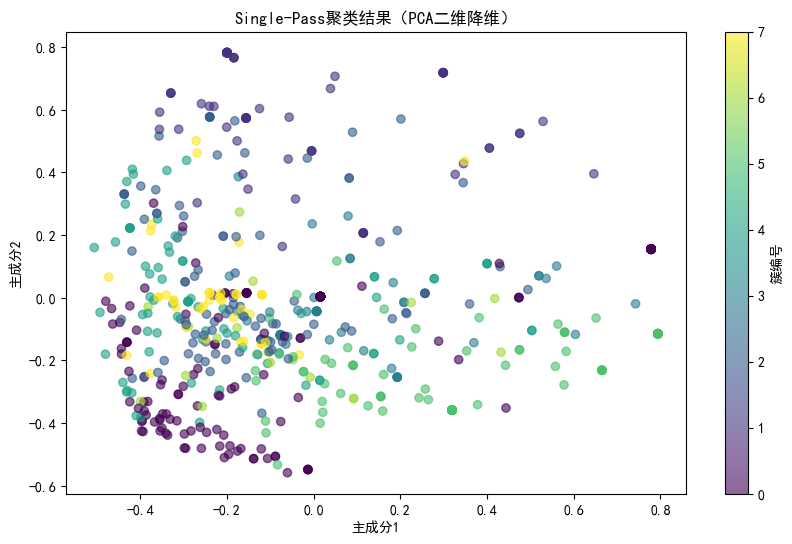

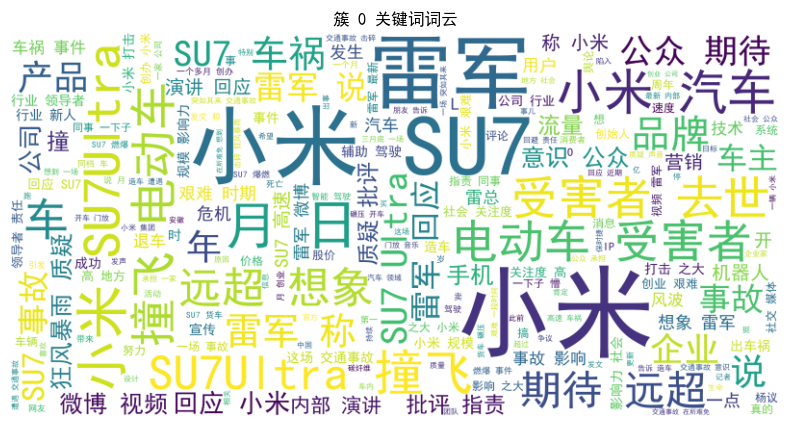

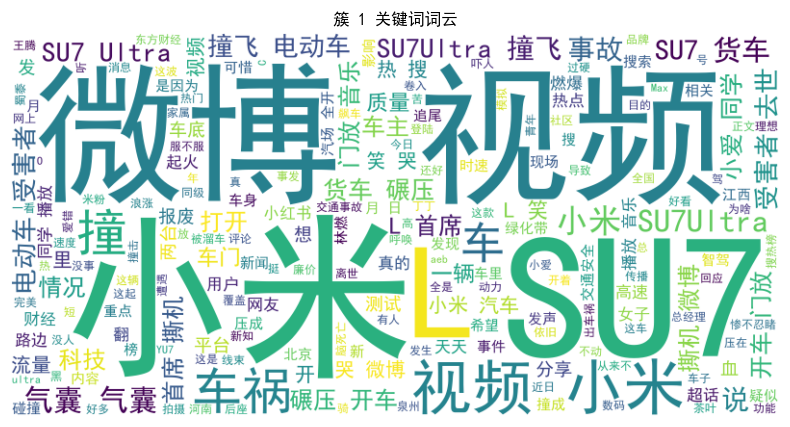

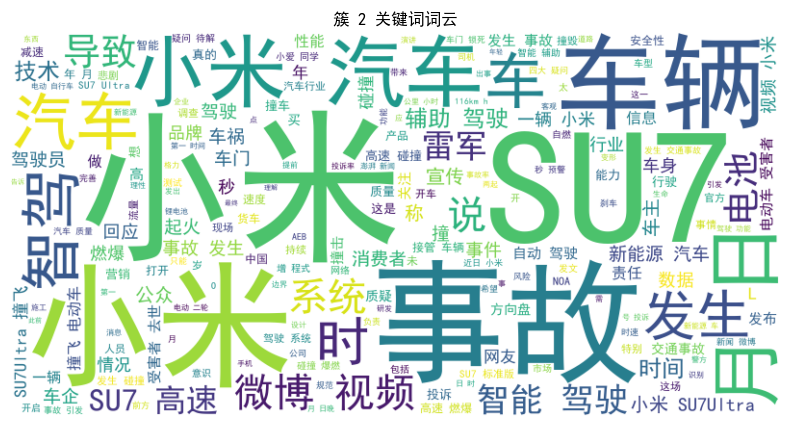

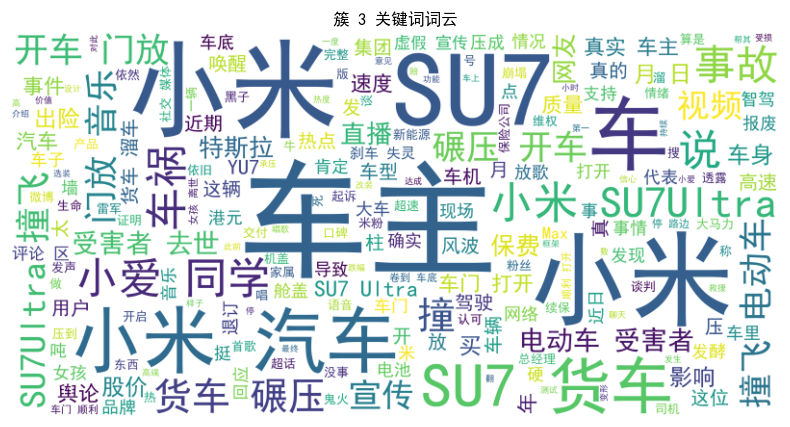

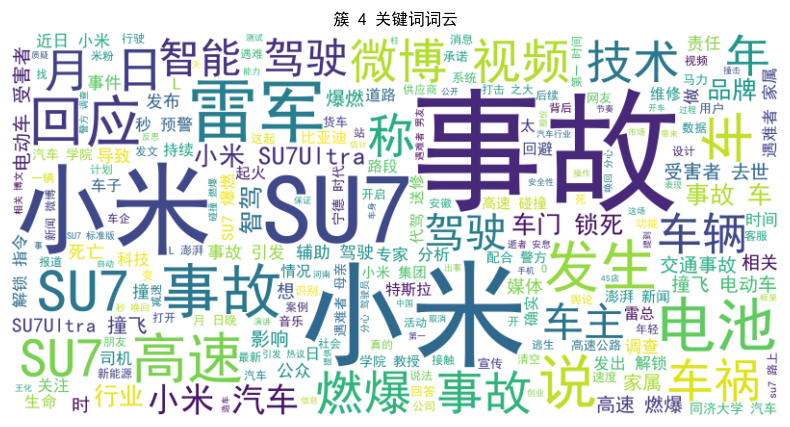

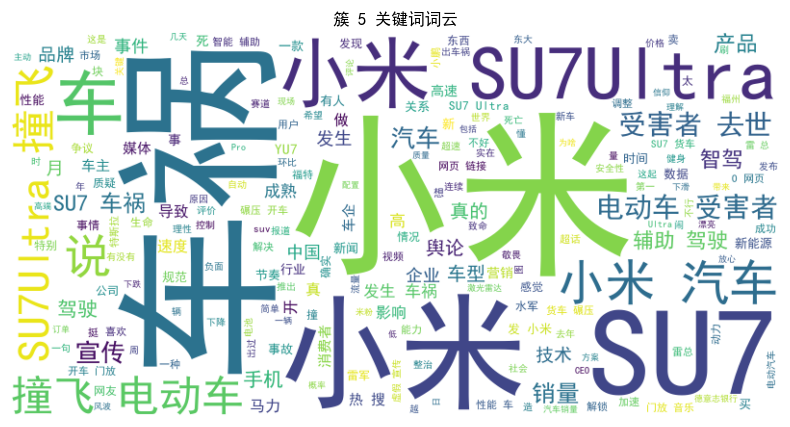

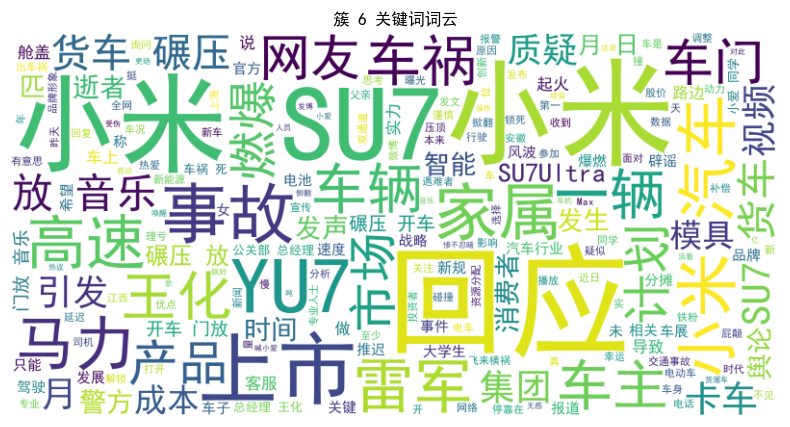

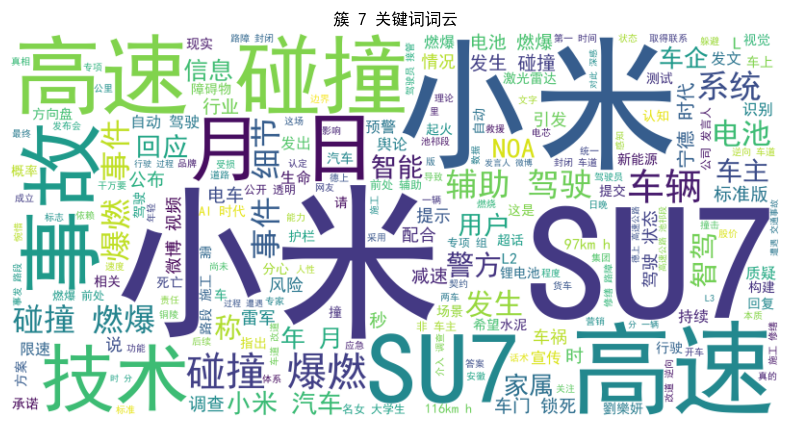

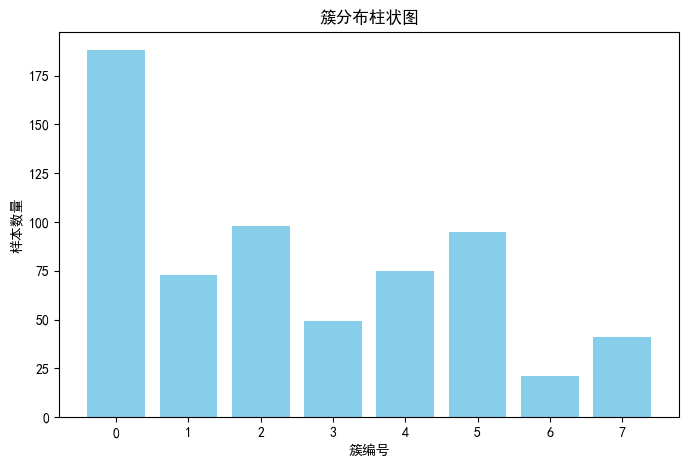

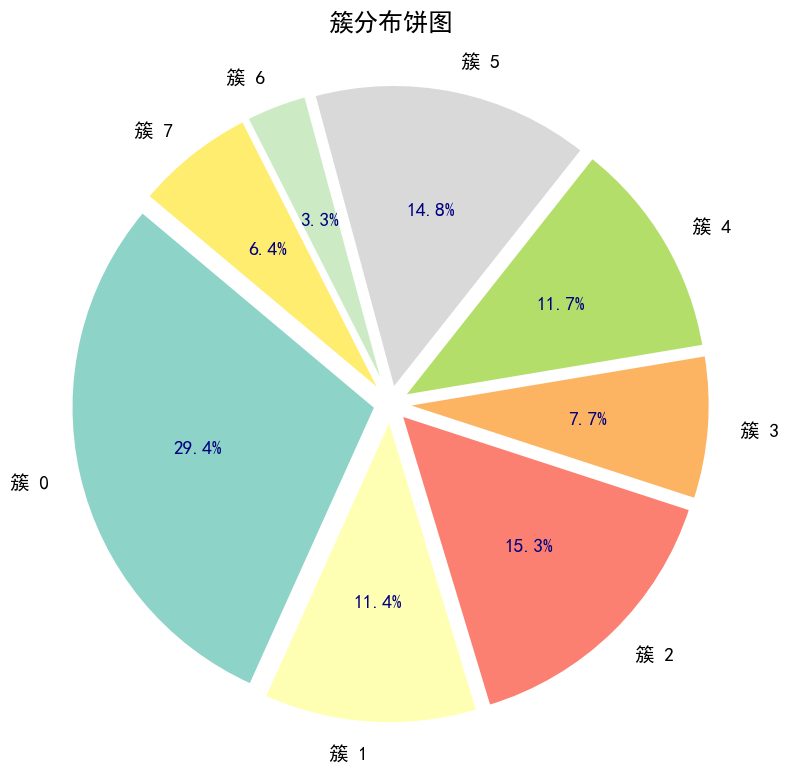

<Figure size 600x500 with 0 Axes>

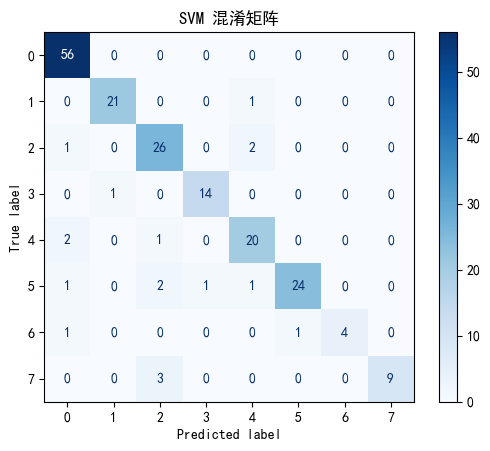

c:\Users\86182\anaconda3\envs\learn\Lib\site-packages\xgboost\training.py:183: UserWarning: [04:24:41] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


<Figure size 600x500 with 0 Axes>

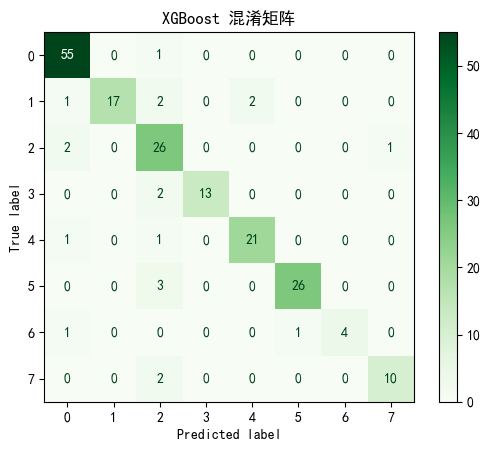

SVM 分类准确率: 0.9062
XGBoost 分类准确率: 0.8958
SVM 分类F1分数: 0.9050
XGBoost 分类F1分数: 0.8970


In [61]:


cluster = SinglePassCluster(stopWords_path='stop_words.txt',
                            max_features=15,
                            max_df=0.5,
                            simi_threshold=0.5)



cluster.single_pass('测试数据.xlsx')